# 02 - Data preparation
## 1. Setup and load

In [44]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

trips = pd.read_csv('../data/trips_all_cities_master.csv')
trips['date'] = pd.to_datetime(trips['date'])

## 2. Hourly aggregation
The target is the number of trips per city and hour, not single trips

In [45]:
demand = (trips.groupby(['city', 'date', 'hour']).size()
               .rename('trips').reset_index())

## 3. Complete grid and zero fills
hours without trips are missing from raw data. Lags below only work if every hour exists.

In [46]:
parts = []
for city, d in trips.groupby('city'):
    days = pd.date_range(d['date'].min(), d['date'].max(), freq='D')
    parts.append(pd.MultiIndex.from_product(
        [[city], days, range(24)], names=['city', 'date', 'hour']
    ).to_frame(index=False))
grid = pd.concat(parts, ignore_index=True)

demand = grid.merge(demand, on=['city', 'date', 'hour'], how='left')
demand['trips'] = demand['trips'].fillna(0).astype(int)

## 4. Sanity checks

In [47]:
print('Rows:', len(demand), '(expected 16128)')
print('Total trips:', demand['trips'].sum(), '(raw:', len(trips), ')')
print('Zero-trip hours:', (demand['trips'] == 0).sum())

Rows: 16128 (expected 16128)
Total trips: 393182 (raw: 393182 )
Zero-trip hours: 1049


## 5. Zero-trip hours

In [48]:
zero = demand[demand['trips'] == 0]
print(zero['hour'].value_counts().sort_index())

hour
0      85
1     146
2     152
3     223
4     181
5      72
6      40
7      15
8      10
9      10
10     12
11      8
12      6
13      6
14      5
15      4
16      4
17      2
18      5
19      6
20      8
21     10
22     10
23     29
Name: count, dtype: int64


In [49]:
print(zero.groupby('city').size())
print((zero.groupby('city').size() / demand.groupby('city').size()).round(3))

city
Badalona         170
Brno              70
Frankfurt        207
Frydek-Mistek    159
Havirov          187
Leon              80
Opava            120
Ostrava           56
dtype: int64
city
Badalona         0.116
Brno             0.032
Frankfurt        0.096
Frydek-Mistek    0.072
Havirov          0.085
Leon             0.055
Opava            0.054
Ostrava          0.025
dtype: float64


In [50]:
day_zero = zero[(zero['hour'] >= 8) & (zero['hour'] <= 20)]
print(day_zero.groupby('date').size().sort_values(ascending=False).head(10))

date
2024-09-20    30
2024-10-11     9
2024-09-14     8
2024-09-04     6
2025-04-28     6
2024-09-21     5
2024-10-08     5
2024-10-05     3
2024-09-13     2
2024-10-23     2
dtype: int64


In [51]:
d = zero[zero['date'] == '2024-09-20']
print(d.groupby('city').size())
print(d['hour'].value_counts().sort_index())

city
Brno              6
Frydek-Mistek     6
Havirov           7
Opava            10
Ostrava           5
dtype: int64
hour
0     1
1     1
3     2
9     5
10    5
11    5
12    5
13    5
14    3
15    1
16    1
Name: count, dtype: int64


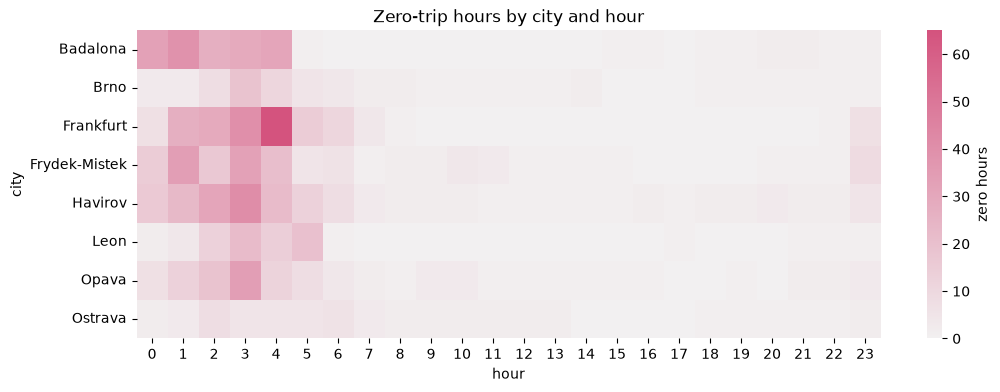

In [52]:
tbl = zero.pivot_table(index='city', columns='hour', values='trips', aggfunc='size', fill_value=0)
plt.figure(figsize=(12, 4))
sns.heatmap(tbl, cmap=sns.light_palette('#D4537E', as_cmap=True), cbar_kws={'label': 'zero hours'})
plt.title('Zero-trip hours by city and hour')
plt.show()

## 6. Calendar features

In [53]:
demand = demand.sort_values(['city', 'date', 'hour']).reset_index(drop=True) # Demand follows a daily and weekly rhythm (seen in EDA). Hour is encoded as sine and cosine so that 23:00 and 00:00 are close
demand['hour_sin'] = np.sin(2 * np.pi * demand['hour'] / 24)
demand['hour_cos'] = np.cos(2 * np.pi * demand['hour'] / 24)
demand['weekday'] = demand['date'].dt.dayofweek
demand['is_weekend'] = (demand['weekday'] >= 5).astype(int)

C:\Users\Наташа Ким\AppData\Local\Temp\ipykernel_15544\1392289656.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  demand['weekday'] = demand['date'].dt.dayofweek


## 7. Public holidays

In [54]:
import holidays

cal_map = {'Brno': ('CZ', None), 'Ostrava': ('CZ', None), 'Opava': ('CZ', None), # Holidays behave like weekends. Each city uses its own country or region calendar
           'Havirov': ('CZ', None), 'Frydek-Mistek': ('CZ', None),
           'Frankfurt': ('DE', 'HE'), 'Badalona': ('ES', 'CT'), 'Leon': ('ES', 'CL')}
cal = {c: holidays.country_holidays(code, subdiv=sub) for c, (code, sub) in cal_map.items()}

demand['is_holiday'] = [int(d.date() in cal[c]) for c, d in zip(demand['city'], demand['date'])]
print(demand.groupby('city')['is_holiday'].sum() / 24)

city
Badalona         3.0
Brno             2.0
Frankfurt        1.0
Frydek-Mistek    2.0
Havirov          2.0
Leon             4.0
Opava            2.0
Ostrava          2.0
Name: is_holiday, dtype: float64


In [55]:
hol = demand[demand['is_holiday'] == 1].groupby('city')['date'].unique()
print(hol)

city
Badalona         [2025-04-18 00:00:00, 2025-04-21 00:00:00, 202...
Brno                    [2024-09-28 00:00:00, 2024-10-28 00:00:00]
Frankfurt                                    [2025-01-01 00:00:00]
Frydek-Mistek           [2024-09-28 00:00:00, 2024-10-28 00:00:00]
Havirov                 [2024-09-28 00:00:00, 2024-10-28 00:00:00]
Leon             [2025-04-17 00:00:00, 2025-04-18 00:00:00, 202...
Opava                   [2024-09-28 00:00:00, 2024-10-28 00:00:00]
Ostrava                 [2024-09-28 00:00:00, 2024-10-28 00:00:00]
Name: date, dtype: object


## 8. Lag features

In [56]:
g = demand.groupby('city')['trips'] # Demand a day and a week ago carries the recent level of demand. All features use data at least 24 hours old, so the forecast is made one day ahead
demand['lag_24'] = g.shift(24)
demand['lag_168'] = g.shift(168)
demand['roll_24'] = g.transform(lambda s: s.shift(24).rolling(24).mean())

demand = demand.dropna(subset=['lag_168', 'roll_24']).reset_index(drop=True)
print('Rows after dropping first week per city:', len(demand))

Rows after dropping first week per city: 14784


## 9. Time-based train / validation / test split

In [57]:
demand['day_no'] = demand.groupby('city')['date'].rank(method='dense') # A random split would leak information from neighbouring hours. Each city is split by date: first 70% of days train, next 15% validation, last 15% test
demand['n_days'] = demand.groupby('city')['date'].transform('nunique')
frac = demand['day_no'] / demand['n_days']
demand['split'] = np.where(frac <= 0.70, 'train', np.where(frac <= 0.85, 'val', 'test'))
demand = demand.drop(columns=['day_no', 'n_days'])

print(demand.groupby(['city', 'split']).size().unstack())

split          test  train  val
city                           
Badalona        216    888  192
Brno            312   1416  312
Frankfurt       312   1392  288
Frydek-Mistek   312   1416  312
Havirov         312   1416  312
Leon            216    888  192
Opava           312   1416  312
Ostrava         312   1416  312


## 10. Flag suspected data collection gap

In [ ]:
czech = ['Brno', 'Ostrava', 'Opava', 'Havirov', 'Frydek-Mistek'] # On 20 September 2024 all five Czech cities record zero trips in the same daytime hours (09:00-13:00). This is unlikely to be real demand and is consistent with the gaps in collection mentioned in the dataset description. The rows are flagged, not deleted, so that the hourly sequence (and the lags) stays intact

gap = (demand['city'].isin(czech)
       & (demand['date'] == '2024-09-20')
       & demand['hour'].between(9, 13))

demand['is_gap'] = gap.astype(int)

print('Flagged rows:', demand['is_gap'].sum(), '(expected 25)')
print('Trips in flagged rows:', demand.loc[gap, 'trips'].sum(), '(expected 0)')

Flagged rows: 25 (expected 25)
Trips in flagged rows: 0 (expected 0)


In [59]:
g = demand.groupby('city')['is_gap']

demand['gap_in_features'] = (
    (g.shift(24) == 1)
    | (g.shift(168) == 1)
    | (g.transform(lambda s: s.shift(24).rolling(24).max()) == 1)
).astype(int)

In [60]:
demand['exclude'] = ((demand['is_gap'] == 1) | (demand['gap_in_features'] == 1)).astype(int)

print(demand.groupby('split')['exclude'].agg(['sum', 'mean']).round(3))

       sum   mean
split            
test     0  0.000
train  190  0.019
val      0  0.000
